# Lab 12: Linear & Logistic Regression using Batch Gradient Descent

**Name:** M. Bilal Tahir
**Roll Number:** i243166

### Task 1: Univariate Linear Regression from Scratch using Batch Gradient Descent (Linear Regression From Scratch)

Shape: (30, 2)
   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0

Missing values per column:
YearsExperience    0
Salary             0
dtype: int64
Shape after removing missing values: (30, 2)
Training samples: 24, Testing samples: 6
Scaling parameters (from training data): min = 1.1, max = 10.5



Learned parameters:
theta0 (intercept) = 35796.7801
theta1 (slope)     = 88692.8798
Initial cost = 3406973406.42
Final cost   = 14757432.97

Test set predictions:
 YearsExperience  Actual Salary  Predicted Salary
             6.8        91738.0          89578.63
             3.2        54445.0          55611.15
             3.9        63218.0          62215.94
             4.5        61111.0          67877.18
             6.0        93940.0          82030.30
             3.0        60150.0          53724.06

Test MSE = 39323613.14
Test R2  = 0.8433


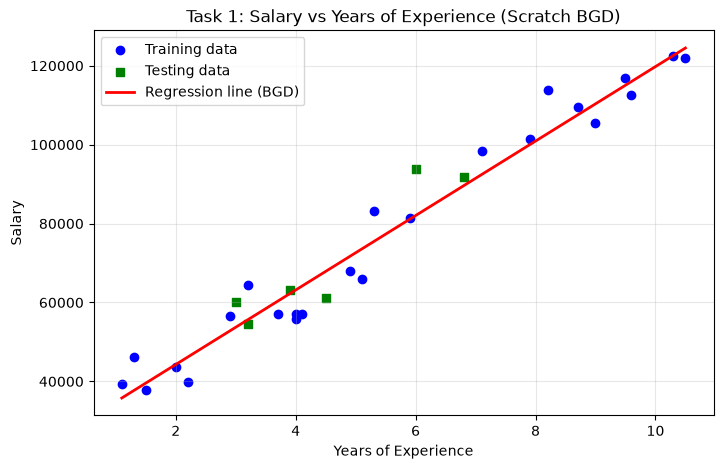

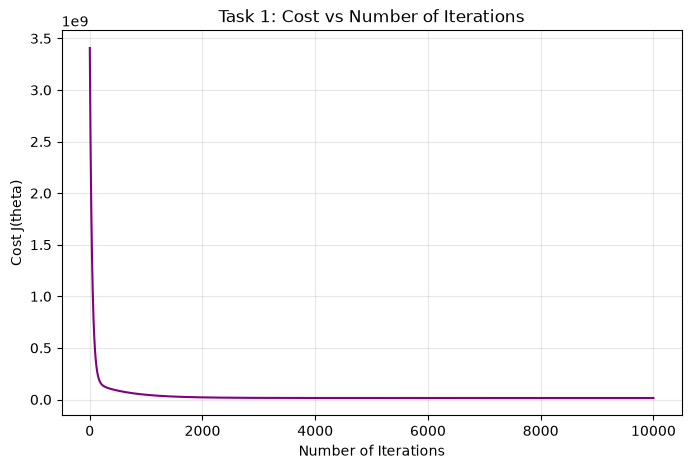

Predicted salary for 5 years of experience: 72594.89


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load dataset
data = pd.read_csv("Salary_Data.csv")

print("Shape:", data.shape)
print(data.head())
print("\nMissing values per column:")
print(data.isnull().sum())

# Step 2: Remove missing values
data = data.dropna().reset_index(drop=True)
print("Shape after removing missing values:", data.shape)

#define x
X = data["YearsExperience"].values.astype(float)
#define y
y = data["Salary"].values.astype(float)

# Step 3: Train-test split (80:20)
np.random.seed(42)

indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

# Separate training and testing indices
train_idx = indices[:split]
test_idx = indices[split:]

# Create X_train, X_test, y_train, y_test
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")


# Step 4: Min-Max normalization
# Calculate minimum and maximum using X_train only (no data leakage)
X_min = X_train.min()
X_max = X_train.max()
print(f"Scaling parameters (from training data): min = {X_min}, max = {X_max}")

# Normalize X_train and X_test using training values
X_train_norm = (X_train - X_min) / (X_max - X_min)
X_test_norm = (X_test - X_min) / (X_max - X_min)


# Step 5: Initialize parameters
m = len(X_train)

theta0 = 0
theta1 = 0

alpha = 0.01
iterations = 10000

cost_history = []


# Step 6: Implement Batch Gradient Descent
for i in range(iterations):

    # Calculate predictions (entire training set every iteration)
    predictions = theta0 + theta1 * X_train_norm

    # Calculate errors
    errors = predictions - y_train

    # Calculate cost and append to cost_history
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    cost_history.append(cost)

    # Calculate gradients for theta0 and theta1
    d_theta0 = (1 / m) * np.sum(errors)
    d_theta1 = (1 / m) * np.sum(errors * X_train_norm)

    # Update theta0 and theta1 (simultaneous update)
    theta0 = theta0 - alpha * d_theta0
    theta1 = theta1 - alpha * d_theta1


# Step 7: Display learned parameters
print("\nLearned parameters:")
print(f"theta0 (intercept) = {theta0:.4f}")
print(f"theta1 (slope)     = {theta1:.4f}")
print(f"Initial cost = {cost_history[0]:.2f}")
print(f"Final cost   = {cost_history[-1]:.2f}")


# Step 8: Predict on test data
y_pred_scratch = theta0 + theta1 * X_test_norm

results_t1 = pd.DataFrame({
    "YearsExperience": X_test,
    "Actual Salary": y_test,
    "Predicted Salary": np.round(y_pred_scratch, 2)
})
print("\nTest set predictions:")
print(results_t1.to_string(index=False))


# Step 9: Calculate MSE and R2 manually
mse_scratch = np.mean((y_test - y_pred_scratch) ** 2)
ss_res = np.sum((y_test - y_pred_scratch) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2_scratch = 1 - ss_res / ss_tot

print(f"\nTest MSE = {mse_scratch:.2f}")
print(f"Test R2  = {r2_scratch:.4f}")


# Step 10: Plot regression line
x_line = np.linspace(X.min(), X.max(), 100)
y_line = theta0 + theta1 * ((x_line - X_min) / (X_max - X_min))

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color="blue", label="Training data")
plt.scatter(X_test, y_test, color="green", marker="s", label="Testing data")
plt.plot(x_line, y_line, color="red", linewidth=2, label="Regression line (BGD)")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Task 1: Salary vs Years of Experience (Scratch BGD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Step 11: Plot cost convergence
plt.figure(figsize=(8, 5))
plt.plot(range(1, iterations + 1), cost_history, color="purple")
plt.xlabel("Number of Iterations")
plt.ylabel("Cost J(theta)")
plt.title("Task 1: Cost vs Number of Iterations")
plt.grid(True, alpha=0.3)
plt.show()


# Step 12: Predict salary for an employee
# with 5 years of experience
experience = 5
experience_norm = (experience - X_min) / (X_max - X_min)
predicted_salary = theta0 + theta1 * experience_norm
print(f"Predicted salary for {experience} years of experience: {predicted_salary:.2f}")

### Task 2: Univariate Linear Regression using Scikit-learn

Training samples: 24, Testing samples: 6

Scikit-learn coefficient (slope) = 88706.9869
Scikit-learn intercept          = 35789.5806

Test MSE = 39326046.04
Test R2  = 0.8433

Prediction comparison on the test set:
 YearsExperience  Actual Salary  Scratch BGD Prediction  Scikit-learn Prediction  Difference
             6.8        91738.0                89578.63                 89579.99        1.35
             3.2        54445.0                55611.15                 55607.10       -4.05
             3.9        63218.0                62215.94                 62212.94       -3.00
             4.5        61111.0                67877.18                 67875.09       -2.10
             6.0        93940.0                82030.30                 82030.46        0.15
             3.0        60150.0                53724.06                 53719.72       -4.35

Parameter and metric comparison:
                        Model    Intercept  Coefficient     Test MSE  Test R2
         Scratch BGD (

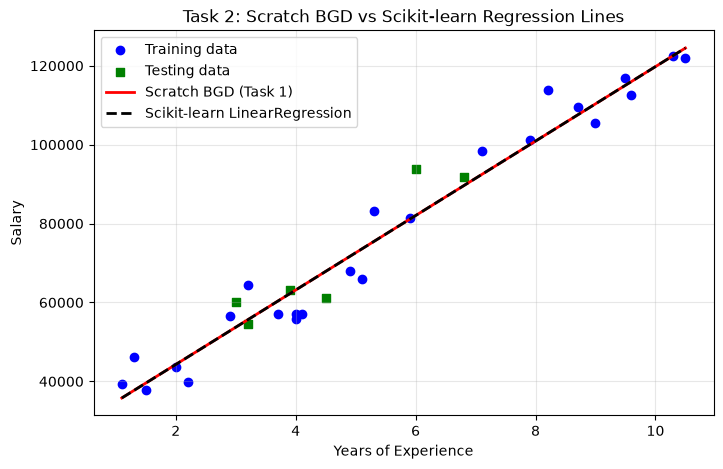

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Load dataset
data = pd.read_csv("Salary_Data.csv")
data = data.dropna().reset_index(drop=True)

# Step 2: Prepare X and y (2D X for scikit-learn)
X = data[["YearsExperience"]].values.astype(float)
y = data["Salary"].values.astype(float)

# Step 3: Perform the same train-test split
# used in Task 1 (80:20, seed / random_state = 42, same indices)
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))
train_idx, test_idx = indices[:split], indices[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

# Step 4: Apply Min-Max normalization
# Use training data statistics only
X_min = X_train.min()
X_max = X_train.max()
X_train_norm = (X_train - X_min) / (X_max - X_min)
X_test_norm = (X_test - X_min) / (X_max - X_min)

# Step 5: Create and train LinearRegression
model = LinearRegression()

# Fit model
model.fit(X_train_norm, y_train)


# Step 6: Generate predictions
y_pred_sklearn = model.predict(X_test_norm)


# Step 7: Display coefficient and intercept
print(f"\nScikit-learn coefficient (slope) = {model.coef_[0]:.4f}")
print(f"Scikit-learn intercept          = {model.intercept_:.4f}")


# Step 8: Calculate MSE and R2
mse_sklearn = mean_squared_error(y_test, y_pred_sklearn)
r2_sklearn = r2_score(y_test, y_pred_sklearn)
print(f"\nTest MSE = {mse_sklearn:.2f}")
print(f"Test R2  = {r2_sklearn:.4f}")


# Step 9: Compare with Task 1
# Use theta0 and theta1 from Task 1

# Generate scratch predictions
y_pred_scratch = theta0 + theta1 * X_test_norm.ravel()

# Create comparison DataFrame
comparison = pd.DataFrame({
    "YearsExperience": X_test.ravel(),
    "Actual Salary": y_test,
    "Scratch BGD Prediction": np.round(y_pred_scratch, 2),
    "Scikit-learn Prediction": np.round(y_pred_sklearn, 2),
    "Difference": np.round(y_pred_sklearn - y_pred_scratch, 2)
})
print("\nPrediction comparison on the test set:")
print(comparison.to_string(index=False))

metrics = pd.DataFrame({
    "Model": ["Scratch BGD (Task 1)", "Scikit-learn LinearRegression"],
    "Intercept": [theta0, model.intercept_],
    "Coefficient": [theta1, model.coef_[0]],
    "Test MSE": [mean_squared_error(y_test, y_pred_scratch), mse_sklearn],
    "Test R2": [r2_score(y_test, y_pred_scratch), r2_sklearn]
})
print("\nParameter and metric comparison:")
print(metrics.to_string(index=False))


# Step 10: Plot both regression lines
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
x_line_norm = (x_line - X_min) / (X_max - X_min)

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color="blue", label="Training data")
plt.scatter(X_test, y_test, color="green", marker="s", label="Testing data")
plt.plot(x_line, theta0 + theta1 * x_line_norm, color="red", linewidth=2,
         label="Scratch BGD (Task 1)")
plt.plot(x_line, model.predict(x_line_norm), color="black", linestyle="--",
         linewidth=2, label="Scikit-learn LinearRegression")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Task 2: Scratch BGD vs Scikit-learn Regression Lines")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Task 2 Discussion: Scratch BGD vs Scikit-learn

- Both models used the **same 24 training / 6 testing samples** and the **same Min-Max scaling** (min = 1.1, max = 10.5 from the training set), so the comparison is fair.
- The learned parameters are almost the same: intercept ≈ 35,797 (BGD) vs 35,790 (sklearn), slope ≈ 88,693 (BGD) vs 88,707 (sklearn). The test predictions differ by only a few units (at most about 4–5 salary units), and both give **R² ≈ 0.8433**. The two regression lines overlap in the plot.
- **Why there is a small difference:** Scikit-learn's `LinearRegression` solves the least-squares problem **directly (closed-form / least-squares solver)**, so it finds the exact minimum of the cost. Batch Gradient Descent is **iterative**: it moves towards the minimum in small steps of size α = 0.01 and stops after 10,000 iterations, so it ends very close to the optimum but not exactly on it. More iterations or a larger learning rate would make the BGD parameters match sklearn even more closely.
- The BGD test MSE is slightly lower than sklearn's here only by chance on 6 test points; on the training data sklearn's solution has the lowest possible cost.

### Task 3: Multivariate Linear Regression using Scikit-learn (Multiple Independent Variables)

Dataset shape: (20640, 9)

First five rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
P

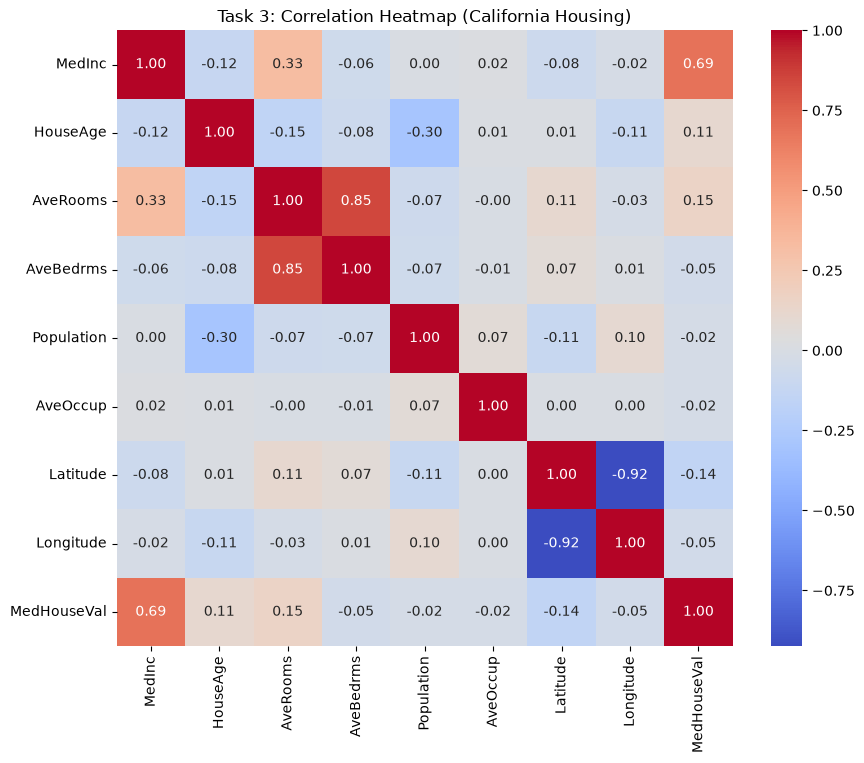

Training samples: 16512, Testing samples: 4128

Test MSE = 0.5559
Test R2  = 0.5758

Intercept = 2.0719

Learned coefficients (standardized features):
   Feature  Coefficient
    MedInc     0.854383
 AveBedrms     0.339259
  HouseAge     0.122546
Population    -0.002308
  AveOccup    -0.040829
  AveRooms    -0.294410
 Longitude    -0.869842
  Latitude    -0.896929

Strongest positive coefficient: MedInc (0.8544)
Strongest negative coefficient: Latitude (-0.8969)


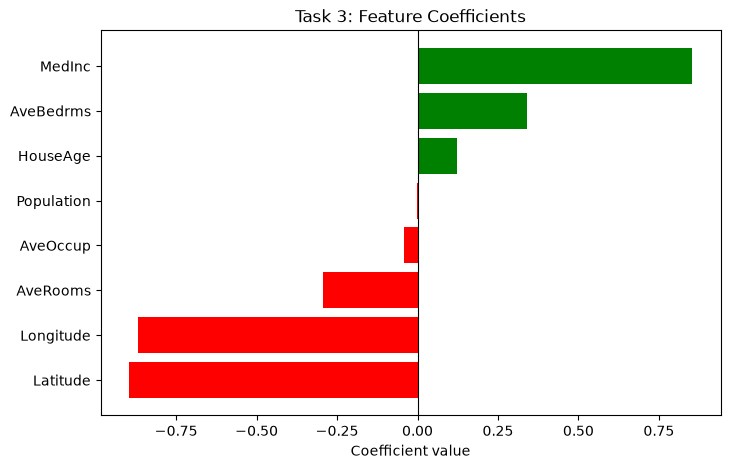


Actual vs predicted (first 10 test samples):
 Actual MedHouseVal  Predicted MedHouseVal  Error
            0.47700                  0.719 -0.242
            0.45800                  1.764 -1.306
            5.00001                  2.710  2.290
            2.18600                  2.839 -0.653
            2.78000                  2.605  0.175
            1.58700                  2.012 -0.425
            1.98200                  2.646 -0.664
            1.57500                  2.169 -0.594
            3.40000                  2.741  0.659
            4.46600                  3.916  0.550


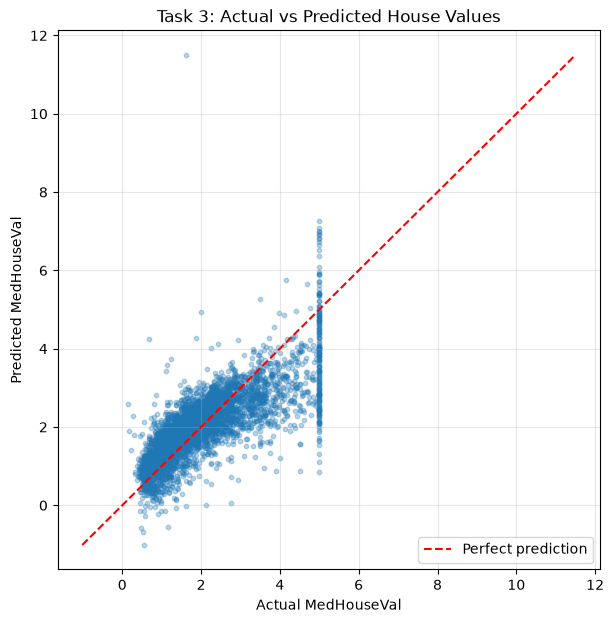

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Load California Housing dataset
housing = fetch_california_housing()

# Step 2: Convert input features into DataFrame
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df["MedHouseVal"] = housing.target

# Step 3: Inspect dataset
# Shape, first five rows, missing values
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nData types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nStatistical summary:")
print(df.describe().round(3))


# Step 4: Generate correlation heatmap
# Include MedHouseVal in the correlation analysis
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Task 3: Correlation Heatmap (California Housing)")
plt.show()


# Step 5: Train-test split (80:20)
X = df[housing.feature_names]
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")


# Step 6: Apply StandardScaler
scaler = StandardScaler()

# Fit scaler on training data
scaler.fit(X_train)
# Transform training and testing data
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Step 7: Train LinearRegression
model = LinearRegression()

# Fit model
model.fit(X_train_scaled, y_train)


# Step 8: Generate predictions
y_pred = model.predict(X_test_scaled)


# Step 9: Evaluate using MSE and R2
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"\nTest MSE = {mse:.4f}")
print(f"Test R2  = {r2:.4f}")


# Step 10: Display feature coefficients
coef_df = pd.DataFrame({
    "Feature": housing.feature_names,
    "Coefficient": model.coef_
}).sort_values("Coefficient", ascending=False).reset_index(drop=True)
print(f"\nIntercept = {model.intercept_:.4f}")
print("\nLearned coefficients (standardized features):")
print(coef_df.to_string(index=False))


# Step 11: Identify strongest positive
# and negative coefficients
strongest_pos = coef_df.iloc[0]
strongest_neg = coef_df.iloc[-1]
print(f"\nStrongest positive coefficient: {strongest_pos['Feature']} ({strongest_pos['Coefficient']:.4f})")
print(f"Strongest negative coefficient: {strongest_neg['Feature']} ({strongest_neg['Coefficient']:.4f})")

plt.figure(figsize=(8, 5))
colors = ["green" if c > 0 else "red" for c in coef_df["Coefficient"]]
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient value")
plt.title("Task 3: Feature Coefficients")
plt.gca().invert_yaxis()
plt.show()


# Step 12: Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual MedHouseVal": y_test.values[:10],
    "Predicted MedHouseVal": np.round(y_pred[:10], 3),
    "Error": np.round(y_test.values[:10] - y_pred[:10], 3)
})
print("\nActual vs predicted (first 10 test samples):")
print(comparison.to_string(index=False))


# Step 13: Plot actual vs predicted values
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.3, s=10)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.title("Task 3: Actual vs Predicted House Values")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Task 3 Interpretation of Feature Influence

- **Dataset overview:** 20,640 samples, 8 numerical input features and the target `MedHouseVal` (in units of $100,000). There are **no missing values**.
- **Performance:** Test MSE ≈ 0.556 and R² ≈ 0.576, so the linear model explains about 58% of the variation in house values. The actual-vs-predicted plot shows the model struggles at high values (the target is capped at 5.0) because the true relationship is not fully linear.
- Because features were standardized, each coefficient is the change in predicted house value (×$100k) for a **one standard deviation** increase in that feature, keeping the others fixed, so the coefficients can be compared with each other.
- **Strongest positive coefficient: `MedInc` (+0.854).** Areas with higher median income have higher house prices. This agrees with the heatmap, where MedInc has the highest correlation with MedHouseVal (≈ 0.69).
- **Strongest negative coefficient: `Latitude` (−0.897)**, closely followed by `Longitude` (−0.870). Moving north or east (away from the expensive coastal areas of Southern California / the Bay Area) lowers the predicted price, so location matters a lot.
- `AveBedrms` is positive (+0.339) while `AveRooms` is negative (−0.294). These two features are strongly correlated with each other (≈ 0.85), so their individual coefficients should be read together rather than alone (multicollinearity).
- `HouseAge` has a small positive effect, while `Population` (≈ 0) and `AveOccup` (−0.04) have very little influence.

### Task 4: Logistic Regression from Scratch using Batch Gradient Descent (from scratch)

Original target names: ['malignant' 'benign']
Feature matrix shape: (569, 30)
Malignant (1): 212, Benign (0): 357
Training matrix with bias: (455, 31)
Initial cost = 0.6931
Final cost   = 0.0539

Learned model parameters:
  bias                      -0.3284
  mean radius                0.5277
  mean texture               0.7453
  mean perimeter             0.5032
  mean area                  0.5798
  mean smoothness            0.4207
  mean compactness          -0.2932
  mean concavity             0.7158
  mean concave points        0.8788
  mean symmetry             -0.0817
  mean fractal dimension    -0.3034
  radius error               1.1758
  texture error             -0.2495
  perimeter error            0.7902
  area error                 0.8784
  smoothness error           0.2010
  compactness error         -0.9018
  concavity error            0.0130
  concave points error       0.3819
  symmetry error            -0.2611
  fractal dimension error   -0.6938
  worst radius        

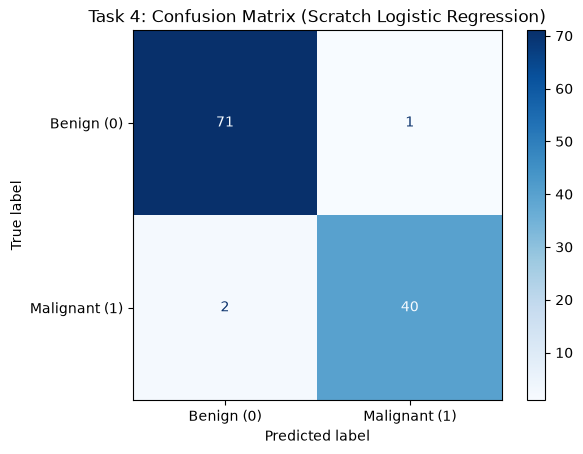

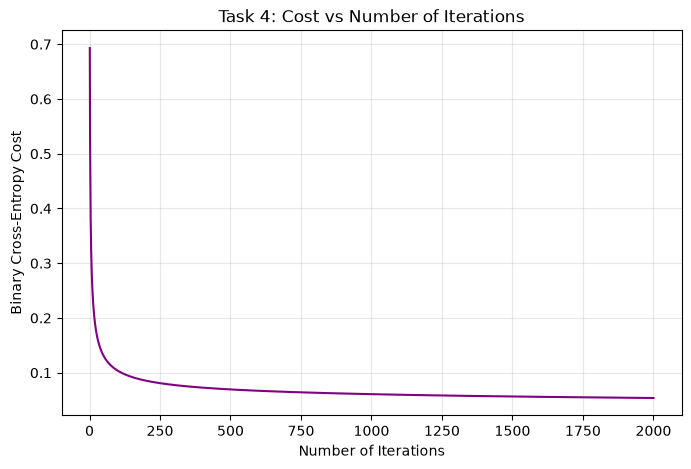

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Step 1: Load dataset
data = load_breast_cancer()

X = data.data

# Encode malignant=1 and benign=0
# (scikit-learn stores malignant=0 and benign=1, so the labels are flipped)
y = (data.target == 0).astype(int)
print("Original target names:", data.target_names)
print("Feature matrix shape:", X.shape)
print(f"Malignant (1): {y.sum()}, Benign (0): {(y == 0).sum()}")


# Step 2: Train-test split
# Use test_size=0.2, random_state=42, stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# Step 3: Feature scaling
scaler = StandardScaler()

# Fit on training data
scaler.fit(X_train)
# Transform training and testing data
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)


# Step 4: Add bias column
X_train = np.hstack([np.ones((X_train.shape[0], 1)), X_train])
X_test = np.hstack([np.ones((X_test.shape[0], 1)), X_test])
print("Training matrix with bias:", X_train.shape)


# Step 5: Initialize parameters
m, n = X_train.shape

theta = np.zeros(n)

alpha = 0.1
iterations = 2000

cost_history = []


# Step 6: Implement sigmoid
def sigmoid(z):

    z = np.clip(z, -500, 500)   # avoid overflow in exp
    return 1 / (1 + np.exp(-z))


# Step 7: Implement binary cross-entropy cost
def compute_cost(y_true, h):

    eps = 1e-15                 # avoid log(0)
    h = np.clip(h, eps, 1 - eps)
    return -np.mean(y_true * np.log(h) + (1 - y_true) * np.log(1 - h))


# Step 8: Implement Batch Gradient Descent
for i in range(iterations):

    # Calculate z
    z = X_train @ theta

    # Calculate sigmoid probabilities
    h = sigmoid(z)

    # Calculate cost
    cost = compute_cost(y_train, h)

    # Store cost
    cost_history.append(cost)

    # Calculate gradient
    gradient = (1 / m) * (X_train.T @ (h - y_train))

    # Update theta
    theta = theta - alpha * gradient


print(f"Initial cost = {cost_history[0]:.4f}")
print(f"Final cost   = {cost_history[-1]:.4f}")

print("\nLearned model parameters:")
param_names = ["bias"] + list(data.feature_names)
for name, value in zip(param_names, theta):
    print(f"  {name:25s} {value: .4f}")


# Step 9: Predict probabilities on test data
y_prob = sigmoid(X_test @ theta)


# Step 10: Apply threshold = 0.5
y_pred = (y_prob >= 0.5).astype(int)


# Step 11: Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nTest-set evaluation (positive class = Malignant):")
print(f"Accuracy  = {accuracy:.4f}")
print(f"Precision = {precision:.4f}")
print(f"Recall    = {recall:.4f}")
print(f"F1-score  = {f1:.4f}")


# Step 12: Generate confusion matrix
# Labels: 0 = Benign, 1 = Malignant
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(cm)
print(f"True Negatives  (Benign predicted Benign)       = {tn}")
print(f"False Positives (Benign predicted Malignant)    = {fp}")
print(f"False Negatives (Malignant predicted Benign)    = {fn}")
print(f"True Positives  (Malignant predicted Malignant) = {tp}")

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["Benign (0)", "Malignant (1)"])
disp.plot(cmap="Blues")
plt.title("Task 4: Confusion Matrix (Scratch Logistic Regression)")
plt.show()


# Step 13: Plot cost vs iterations
plt.figure(figsize=(8, 5))
plt.plot(range(1, iterations + 1), cost_history, color="purple")
plt.xlabel("Number of Iterations")
plt.ylabel("Binary Cross-Entropy Cost")
plt.title("Task 4: Cost vs Number of Iterations")
plt.grid(True, alpha=0.3)
plt.show()

#### Task 4 Interpretation of False Positives and False Negatives

- The cost drops smoothly from **0.693** (all parameters zero, so every probability is 0.5) to about **0.054**, showing that Batch Gradient Descent converged.
- Test results (positive class = Malignant): **Accuracy 97.37%, Precision 97.56%, Recall 95.24%, F1 96.39%**.
- **False Positive (1 case):** a benign tumor was predicted as malignant. This leads to extra tests or a biopsy and patient stress, but the patient is not put in danger.
- **False Negative (2 cases):** a malignant tumor was predicted as benign. This is the **more dangerous error**, because a cancer patient could miss or delay treatment.
- That is why **recall for the malignant class** is the most important metric here. The model detects 40 of 42 malignant tumors (recall ≈ 95.2%). If we want even fewer false negatives, we can lower the threshold below 0.5; this raises recall at the cost of more false positives.

### Task 5: Customer Churn Prediction Using Logistic Regression

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

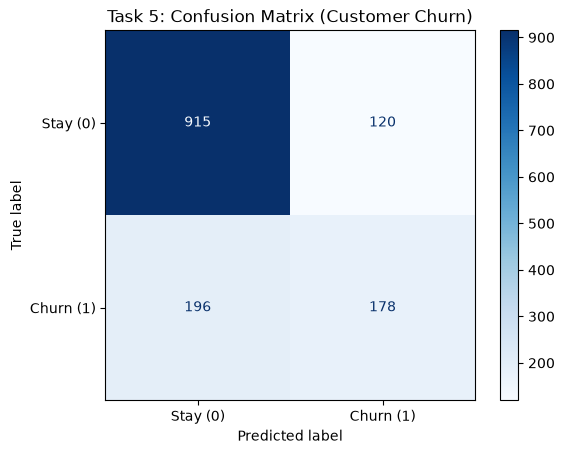


New customer:
 tenure  MonthlyCharges  TotalCharges       Contract InternetService
      3            85.5         256.5 Month-to-month     Fiber optic

Predicted probability of churn: 0.6780 (67.80%)
Prediction: CHURN (customer is likely to leave)


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# 2. Load Dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.head())

print("\nDataset dimensions:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nTarget variable: 'Churn'")
print(df["Churn"].value_counts())


# 3. Data Preprocessing
# TotalCharges is stored as text; blank strings become NaN after conversion
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nMissing TotalCharges after conversion:", df["TotalCharges"].isnull().sum())
print(df.loc[df["TotalCharges"].isnull(), ["tenure", "MonthlyCharges", "TotalCharges"]])

# All missing rows have tenure = 0 (new customers not billed yet),
# so their total charges so far are 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing TotalCharges after handling:", df["TotalCharges"].isnull().sum())

# Encode target: Yes = 1, No = 0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print("\nEncoded Churn distribution:")
print(df["Churn"].value_counts())


# 4. Select Features and Target
features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Contract",
    "InternetService"
]

X = df[features]
y = df["Churn"]

# 5. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTraining samples: {len(X_train)}, Testing samples: {len(X_test)}")
print("Churn rate - train: {:.3f}, test: {:.3f}".format(y_train.mean(), y_test.mean()))

# 6. Feature Preprocessing
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    "Contract",
    "InternetService"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# 7. Create and Train Model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
print("\nModel trained successfully!")


# Save trained model
joblib.dump(model, "churn_model.pkl")
print("Trained model saved to churn_model.pkl")


###################
# Load saved model
loaded_model = joblib.load("churn_model.pkl")

print("Trained model loaded successfully!")

# 8. Make Predictions
y_pred = loaded_model.predict(X_test)


# 9. Model Evaluation
print(f"\nAccuracy  = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall    = {recall_score(y_test, y_pred):.4f}")
print(f"F1-score  = {f1_score(y_test, y_pred):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Stay (0)", "Churn (1)"]))


# 10. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Stay (0)", "Churn (1)"])
disp.plot(cmap="Blues")
plt.title("Task 5: Confusion Matrix (Customer Churn)")
plt.show()


# 11. Predict whether a new customer will churn or stay
new_customer = pd.DataFrame([{
    "tenure": 3,
    "MonthlyCharges": 85.50,
    "TotalCharges": 256.50,
    "Contract": "Month-to-month",
    "InternetService": "Fiber optic"
}])
print("\nNew customer:")
print(new_customer.to_string(index=False))

churn_prob = loaded_model.predict_proba(new_customer)[0, 1]
prediction = loaded_model.predict(new_customer)[0]
print(f"\nPredicted probability of churn: {churn_prob:.4f} ({churn_prob * 100:.2f}%)")
print("Prediction:", "CHURN (customer is likely to leave)" if prediction == 1
      else "STAY (customer is likely to continue)")

#### Task 5 Summary

- The dataset has 7,043 customers and 21 columns; the target variable is **`Churn`** (26.5% Yes). `TotalCharges` was stored as text; converting it to numbers produced 11 missing values, all for customers with `tenure = 0` (not billed yet), so they were filled with 0.
- The stratified split keeps the same churn rate (26.5%) in both training and testing sets.
- The model reaches **77.6% accuracy** with **precision 0.597, recall 0.476 and F1 0.530** for the churn class. Recall is lower because churners are the minority class and only five features were used; the model misses 196 of 374 churners (false negatives).
- The trained pipeline (scaler + one-hot encoder + logistic regression) was saved to `churn_model.pkl` with `joblib` and loaded back before predicting.
- A new customer with 3 months tenure, a month-to-month contract, fiber-optic internet and high monthly charges gets a **churn probability of about 67.8%**, so the model predicts that this customer will **churn**.